<a href="https://colab.research.google.com/github/arielsharonferdinandus/AirQualityCO_PredictiveAnalytics/blob/data-dictionary/AirQualityCO_PredictiveAnalytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predictive Analytics Group Project: Estimating Carbon Monoxide (CO) from Air Quality Sensors

**Group number :** 4  
**Member :**

| No. | Nama | NIM |  |
|:---:|---|:---:|---|
| 1 | **ZAKY HAFIEDZ** | 24130500006 | Ketua |
| 2 | **ARIEL SHARON FERDINANDUS** | 24130500007
| 3 | **ZULFIKAR DITYA ANTARIKSA** | 24120500006 |

**Theme:** Energy and Environment  
**Dataset:** Air Quality UCI (UCI Machine Learning Repository, dataset id 360)

**Notebook structure**
1. Project setup and registration
2. Data understanding and quality assessment
3. Data preparation
4. Exploratory data analysis
5. Feature engineering
6. Baseline and candidate models
7. Validation and hyperparameter tuning
8. Final evaluation and interpretation
9. Findings and recommendations

---
## 1. Project Setup and Registration

### 1.1 Stakeholder and prediction question

**Stakeholder:** An urban environmental monitoring team that operates a multi-sensor air quality station in an Italian city.

**Problem:** Reference-grade CO analyzers are expensive, need frequent calibration and are often offline, which leaves gaps in the reference record. Low-cost metal-oxide sensors and meteorological probes keep running.

**Prediction question:** *Can we estimate the hourly reference CO concentration, `CO(GT)` (mg/m³), from the same-hour low-cost sensor responses, weather conditions and time-of-day features, accurately enough to fill reference gaps and flag high-CO hours for follow-up?*

### 1.2 Task framing (decision to confirm as a group)

| Item | Choice |
|---|---|
| Prediction type | Regression |
| Target | `CO(GT)`, reference CO concentration in mg/m³ |
| Unit of analysis | One hourly observation |
| Use case | **Same-hour estimation (nowcasting / gap-filling)**, not future forecasting |
| Primary metrics | MAE and RMSE (mg/m³); R² as supporting evidence |
| Validation | Chronological split (train, validation, test) to test temporal generalisation, decided in Part 6/7 |

**Why same-hour estimation:** using contemporaneous sensor readings (`PT08.*`) as predictors is legitimate only if the model is meant to estimate CO *at the same time* the sensors are read. Using `NOx(GT)`, `NO2(GT)` and `C6H6(GT)` is also same-hour, but those are reference-analyzer outputs that may be missing exactly when `CO(GT)` is missing. We will test this in Part 5 and may compare feature sets: (a) low-cost sensors + weather + time only, and (b) adding reference pollutants.

If the group prefers future forecasting instead, the target must be shifted by a defined horizon and every predictor must come from earlier hours. We would change the framing in Parts 5 and 7 and document it.

### 1.3 Registration checklist
- [ ] Register dataset and target at `s.id/listdatapred02`
- [ ] Verify no other group registered the same dataset
- [ ] Confirm it was not used in the individual midterm project
- [ ] Confirm source, publisher, source URL, access date (recorded below from the repository metadata)

### 1.4 Setup: installs, imports, global settings

In [9]:
# Installation (needed in Colab; harmless elsewhere)
!pip install -q ucimlrepo openpyxl

In [10]:
import os
import random
import warnings
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 150)
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

DATA_DIR = 'data'                       # relative path, works in Colab and locally
os.makedirs(DATA_DIR, exist_ok=True)
print('Setup complete. Access date:', date.today().isoformat())

Setup complete. Access date: 2026-10-15


### 1.5 Load the data from the original repository

Source: UCI Machine Learning Repository, *Air Quality* (id 360), https://archive.ics.uci.edu/dataset/360/air+quality. We use the `ucimlrepo` package so the notebook downloads the data itself and needs no manual upload.

In [11]:
# Fetch dataset from UCI (needs internet access)
air_quality = fetch_ucirepo(id=360)
ACCESS_DATE = date.today().isoformat()

# Repository metadata
meta = air_quality.metadata
for key in ['uci_id', 'name', 'repository_url', 'data_url', 'abstract', 'area',
            'task', 'num_instances', 'num_features', 'has_missing_values',
            'creators', 'year_of_dataset_creation', 'doi']:
    print(f'{key}: {meta.get(key)}')

uci_id: 360
name: Air Quality
repository_url: https://archive.ics.uci.edu/dataset/360/air+quality
data_url: https://archive.ics.uci.edu/static/public/360/data.csv
abstract: Contains the responses of a gas multisensor device deployed on the field in an Italian city. Hourly responses averages are recorded along with gas concentrations references from a certified analyzer. 
area: Computer Science
task: None
num_instances: 9358
num_features: 15
has_missing_values: no
creators: ['Saverio Vito']
year_of_dataset_creation: 2008
doi: None


In [12]:
# Variable descriptions supplied by the repository (units, roles, missing flags)
air_quality.variables

,name,role,type,demographic,description,units,missing_values
0,Date,Feature,Date,None,None,None,no
1,Time,Feature,Categorical,None,None,None,no
2,CO(GT),Feature,Integer,None,True hourly averaged concentration CO in mg/m^...,mg/m^3,no
3,PT08.S1(CO),Feature,Categorical,None,hourly averaged sensor response (nominally CO...,None,no
4,NMHC(GT),Feature,Integer,None,True hourly averaged overall Non Metanic Hydro...,microg/m^3,no
5,C6H6(GT),Feature,Continuous,None,True hourly averaged Benzene concentration in...,microg/m^3,no
6,PT08.S2(NMHC),Feature,Categorical,None,hourly averaged sensor response (nominally NMH...,None,no
7,NOx(GT),Feature,Integer,None,True hourly averaged NOx concentration in ppb...,ppb,no
8,PT08.S3(NOx),Feature,Categorical,None,hourly averaged sensor response (nominally NOx...,None,no
9,NO2(GT),Feature,Integer,None,True hourly averaged NO2 concentration in micr...,microg/m^3,no


In [13]:
# Build one raw DataFrame. ucimlrepo may return everything in .features
# or split features/targets, so we combine whatever is present.
X = air_quality.data.features
y = air_quality.data.targets
print('features:', None if X is None else X.shape, '| targets:', None if y is None else y.shape)

parts = [p for p in (X, y) if p is not None and p.shape[1] > 0]
df_raw = pd.concat(parts, axis=1)

print('\nCombined raw shape:', df_raw.shape)
df_raw.head()

features: (9357, 15) | targets: None

Combined raw shape: (9357, 15)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,3/10/2004,18:00:00,2.6,1360,150,11.9,1046,166,1056,113,1692,1268,13.6,48.9,0.7578
1,3/10/2004,19:00:00,2.0,1292,112,9.4,955,103,1174,92,1559,972,13.3,47.7,0.7255
2,3/10/2004,20:00:00,2.2,1402,88,9.0,939,131,1140,114,1555,1074,11.9,54.0,0.7502
3,3/10/2004,21:00:00,2.2,1376,80,9.2,948,172,1092,122,1584,1203,11.0,60.0,0.7867
4,3/10/2004,22:00:00,1.6,1272,51,6.5,836,131,1205,116,1490,1110,11.2,59.6,0.7888


### 1.6 Verify the data matches the project brief

Expected: 9,357 rows x 15 columns, the 15 named columns, and date coverage 10 March 2004 to 4 April 2005.

In [14]:
expected_cols = ['Date', 'Time', 'CO(GT)', 'NMHC(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)',
                 'PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 'PT08.S4(NO2)',
                 'PT08.S5(O3)', 'T', 'RH', 'AH']

print('Shape matches (9357, 15):', df_raw.shape == (9357, 15))
print('Missing expected columns:', [c for c in expected_cols if c not in df_raw.columns])
print('Unexpected extra columns:', [c for c in df_raw.columns if c not in expected_cols])

df_raw = df_raw[[c for c in expected_cols if c in df_raw.columns]]   # fixed column order

print('\nData types:')
print(df_raw.dtypes)

print('\nDate range (as stored):', df_raw['Date'].iloc[0], '->', df_raw['Date'].iloc[-1])

Shape matches (9357, 15): True
Missing expected columns: []
Unexpected extra columns: []

Data types:
Date              object
Time              object
CO(GT)           float64
NMHC(GT)           int64
C6H6(GT)         float64
NOx(GT)            int64
NO2(GT)            int64
PT08.S1(CO)        int64
PT08.S2(NMHC)      int64
PT08.S3(NOx)       int64
PT08.S4(NO2)       int64
PT08.S5(O3)        int64
T                float64
RH               float64
AH               float64
dtype: object

Date range (as stored): 3/10/2004 -> 4/4/2005


### 1.7 Save the exact file used for analysis

The submission must include `AirQualityUCI.xlsx`. We write the raw data exactly as downloaded to that file name so the ZIP contains the data the notebook used. No cleaning has been applied at this point (the `-200` handling is done in Part 2/3).

In [15]:
xlsx_path = os.path.join(DATA_DIR, 'AirQualityUCI.xlsx')
df_raw.to_excel(xlsx_path, sheet_name='AirQualityUCI', index=False)
print('Saved:', xlsx_path)

# Reload from the saved file to prove the pipeline reproduces from the file
df = pd.read_excel(xlsx_path, sheet_name='AirQualityUCI')
print('Reloaded shape:', df.shape)

Saved: data/AirQualityUCI.xlsx
Reloaded shape: (9357, 15)


### 1.8 Dataset registration record
Copy these values into the registration form at `s.id/listdatapred02`.

In [16]:
predictors = [c for c in df.columns if c not in ('CO(GT)',)]

registration = {
    'Dataset title': meta.get('name'),
    'Publisher / repository': 'UCI Machine Learning Repository',
    'Creators': meta.get('creators'),
    'Source URL': meta.get('repository_url') or 'https://archive.ics.uci.edu/dataset/360/air+quality',
    'Access date': ACCESS_DATE,
    'Rows x columns': f'{df.shape[0]} x {df.shape[1]}',
    'Date coverage': '10 March 2004 to 4 April 2005 (verify in Part 2)',
    'Prediction type': 'Regression',
    'Target': 'CO(GT)',
    'Candidate predictors': ', '.join(predictors),
}
pd.Series(registration, name='Value').to_frame()

,Value
Dataset title,Air Quality
Publisher / repository,UCI Machine Learning Repository
Creators,[Saverio Vito]
Source URL,https://archive.ics.uci.edu/dataset/360/air+qu...
Access date,2026-10-15
Rows x columns,9357 x 15
Date coverage,10 March 2004 to 4 April 2005 (verify in Part 2)
Prediction type,Regression
Target,CO(GT)
Candidate predictors,"Date, Time, NMHC(GT), C6H6(GT), NOx(GT), NO2(G..."


**Part 1 status:** data imported from the original repository, shape and columns checked, raw data saved as `data/AirQualityUCI.xlsx`, registration values recorded.

**Next (Part 2):** data dictionary, `-200` sentinel investigation, missing-value report, duplicate/timestamp/gap checks, and target distribution.

---
## 2. Data Understanding and Quality Assessment

### 2.1 Reload the exact analysis file and verify basic structure
We always start from `data/AirQualityUCI.xlsx` (saved in Part 1), so every later step is reproducible from the submitted file.

In [17]:
XLSX_PATH = os.path.join(DATA_DIR, 'AirQualityUCI.xlsx')
SHEET_NAME = 'AirQualityUCI'

df_raw = pd.read_excel(XLSX_PATH, sheet_name=SHEET_NAME)

print('Sheet name      :', SHEET_NAME)
print('Shape           :', df_raw.shape)
print('Columns         :', list(df_raw.columns))
print('Duplicate rows  :', df_raw.duplicated().sum())
print()
df_raw.info()
df_raw.head()

Sheet name      : AirQualityUCI
Shape           : (9357, 15)
Columns         : ['Date', 'Time', 'CO(GT)', 'NMHC(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)', 'PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']
Duplicate rows  : 0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   object 
 1   Time           9357 non-null   object 
 2   CO(GT)         9357 non-null   float64
 3   NMHC(GT)       9357 non-null   int64  
 4   C6H6(GT)       9357 non-null   float64
 5   NOx(GT)        9357 non-null   int64  
 6   NO2(GT)        9357 non-null   int64  
 7   PT08.S1(CO)    9357 non-null   int64  
 8   PT08.S2(NMHC)  9357 non-null   int64  
 9   PT08.S3(NOx)   9357 non-null   int64  
 10  PT08.S4(NO2)   9357 non-null   int64  
 11  PT08.S5(O3)    9357 non-null   int64  
 12  T  

,Date,Time,CO(GT),NMHC(GT),C6H6(GT),NOx(GT),NO2(GT),PT08.S1(CO),PT08.S2(NMHC),PT08.S3(NOx),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,3/10/2004,18:00:00,2.6,150,11.9,166,113,1360,1046,1056,1692,1268,13.6,48.9,0.7578
1,3/10/2004,19:00:00,2.0,112,9.4,103,92,1292,955,1174,1559,972,13.3,47.7,0.7255
2,3/10/2004,20:00:00,2.2,88,9.0,131,114,1402,939,1140,1555,1074,11.9,54.0,0.7502
3,3/10/2004,21:00:00,2.2,80,9.2,172,122,1376,948,1092,1584,1203,11.0,60.0,0.7867
4,3/10/2004,22:00:00,1.6,51,6.5,131,116,1272,836,1205,1490,1110,11.2,59.6,0.7888


### 2.2 Data dictionary
Descriptions follow the UCI repository documentation. `GT` = ground truth (reference analyzer); `PT08.*` = low-cost metal-oxide sensor responses (nominal units, not concentrations).

In [18]:
data_dictionary = pd.DataFrame([
    ('Date',          'Date of observation',                                 'date',        'Time index'),
    ('Time',          'Hour of observation',                                 'hh:mm:ss',    'Time index'),
    ('CO(GT)',        'True hourly mean CO concentration (reference)',       'mg/m^3',      'TARGET'),
    ('PT08.S1(CO)',   'Tin oxide sensor, nominally CO-targeted',             'sensor resp.', 'Predictor'),
    ('NMHC(GT)',      'True hourly mean non-metanic hydrocarbons (reference)', 'microg/m^3', 'Candidate (very high missingness)'),
    ('C6H6(GT)',      'True hourly mean benzene (reference)',                'microg/m^3',  'Candidate predictor'),
    ('PT08.S2(NMHC)', 'Titania sensor, nominally NMHC-targeted',             'sensor resp.', 'Predictor'),
    ('NOx(GT)',       'True hourly mean NOx (reference)',                    'ppb',         'Candidate predictor'),
    ('PT08.S3(NOx)',  'Tungsten oxide sensor, nominally NOx-targeted',       'sensor resp.', 'Predictor'),
    ('NO2(GT)',       'True hourly mean NO2 (reference)',                    'microg/m^3',  'Candidate predictor'),
    ('PT08.S4(NO2)',  'Tungsten oxide sensor, nominally NO2-targeted',       'sensor resp.', 'Predictor'),
    ('PT08.S5(O3)',   'Indium oxide sensor, nominally O3-targeted',          'sensor resp.', 'Predictor'),
    ('T',             'Temperature',                                         'deg C',       'Predictor (weather)'),
    ('RH',            'Relative humidity',                                   '%',           'Predictor (weather)'),
    ('AH',            'Absolute humidity',                                   'g/m^3 (as published)', 'Predictor (weather)'),
], columns=['Column', 'Description', 'Unit', 'Role'])

missing_from_dict = set(df_raw.columns) - set(data_dictionary['Column'])
print('Columns not in dictionary:', missing_from_dict or 'none')
data_dictionary

Columns not in dictionary: none


,Column,Description,Unit,Role
0,Date,Date of observation,date,Time index
1,Time,Hour of observation,hh:mm:ss,Time index
2,CO(GT),True hourly mean CO concentration (reference),mg/m^3,TARGET
3,PT08.S1(CO),"Tin oxide sensor, nominally CO-targeted",sensor resp.,Predictor
4,NMHC(GT),True hourly mean non-metanic hydrocarbons (ref...,microg/m^3,Candidate (very high missingness)
5,C6H6(GT),True hourly mean benzene (reference),microg/m^3,Candidate predictor
6,PT08.S2(NMHC),"Titania sensor, nominally NMHC-targeted",sensor resp.,Predictor
7,NOx(GT),True hourly mean NOx (reference),ppb,Candidate predictor
8,PT08.S3(NOx),"Tungsten oxide sensor, nominally NOx-targeted",sensor resp.,Predictor
9,NO2(GT),True hourly mean NO2 (reference),microg/m^3,Candidate predictor


### 2.3 Investigating the `-200` value
The brief says `-200` is likely a missing-value sentinel. We check this with evidence rather than assuming it: how often does it occur, in which columns, and is it physically possible?

In [19]:
num_cols = [c for c in df_raw.columns if c not in ('Date', 'Time')]

# Make sure numeric columns are numeric (decimal commas or stray text would show up here)
for c in num_cols:
    if not pd.api.types.is_numeric_dtype(df_raw[c]):
        print(f'Converting {c} from {df_raw[c].dtype} to numeric')
        df_raw[c] = pd.to_numeric(df_raw[c].astype(str).str.replace(',', '.', regex=False), errors='coerce')

n = len(df_raw)
evidence = pd.DataFrame({
    'count_-200': (df_raw[num_cols] == -200).sum(),
    'pct_-200': ((df_raw[num_cols] == -200).mean() * 100).round(2),
    'already_NaN': df_raw[num_cols].isna().sum(),
    'min_excluding_-200': df_raw[num_cols].where(df_raw[num_cols] != -200).min(),
    'max': df_raw[num_cols].max(),
})
evidence

,count_-200,pct_-200,already_NaN,min_excluding_-200,max
CO(GT),1683,17.99,0,0.1000,11.900
NMHC(GT),8443,90.23,0,7.0000,1189.000
C6H6(GT),366,3.91,0,0.1000,63.700
NOx(GT),1639,17.52,0,2.0000,1479.000
NO2(GT),1642,17.55,0,2.0000,340.000
PT08.S1(CO),366,3.91,0,647.0000,2040.000
PT08.S2(NMHC),366,3.91,0,383.0000,2214.000
PT08.S3(NOx),366,3.91,0,322.0000,2683.000
PT08.S4(NO2),366,3.91,0,551.0000,2775.000
PT08.S5(O3),366,3.91,0,221.0000,2523.000


In [20]:
# Evidence 1: -200 is far below the minimum of the other values in every column
#             (a CO concentration, humidity or sensor response cannot be -200).
# Evidence 2: it is the ONLY negative value that repeats, it is the same number in all columns.
neg = df_raw[num_cols][df_raw[num_cols] < 0].stack()
print('Distinct negative values in the whole table and how often they occur:')
print(neg.value_counts().head(10))

# Evidence 3: -200 clusters in the same rows (whole sensor/analyzer outages).
rows_with_200 = (df_raw[num_cols] == -200)
print('\nRows with at least one -200:', rows_with_200.any(axis=1).sum())
print('Rows where ALL numeric columns are -200:', rows_with_200.all(axis=1).sum())
print('\nNumber of -200 per row (distribution):')
print(rows_with_200.sum(axis=1).value_counts().sort_index())

Distinct negative values in the whole table and how often they occur:
-200.0    16701
-0.1          2
-0.6          2
-1.3          2
-0.3          1
-1.1          1
-0.2          1
-1.4          1
-1.2          1
-1.9          1
Name: count, dtype: int64

Rows with at least one -200: 8530
Rows where ALL numeric columns are -200: 31

Number of -200 per row (distribution):
0      827
1     6138
2      467
3      364
4     1195
9       26
10     291
11       6
12      12
13      31
Name: count, dtype: int64


**Decision (to confirm after reading the output above):** `-200` is treated as a missing-value sentinel in all numeric columns and replaced by `NaN`. It is not a physical reading: it is far outside the observed range of every variable, is the same number across unrelated quantities (concentration, temperature, humidity), and frequently appears in several columns of the same hour, which is typical of an instrument outage. The original file is kept untouched; the cleaned copy is `df`.

### 2.4 Replace the sentinel and report missing values

In [21]:
df = df_raw.copy()
df[num_cols] = df[num_cols].replace(-200, np.nan)

missing_report = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_pct': (df.isna().mean() * 100).round(2),
    'usable_count': df.notna().sum(),
}).sort_values('missing_pct', ascending=False)
missing_report

,missing_count,missing_pct,usable_count
NMHC(GT),8443,90.23,914
CO(GT),1683,17.99,7674
NO2(GT),1642,17.55,7715
NOx(GT),1639,17.52,7718
C6H6(GT),366,3.91,8991
PT08.S2(NMHC),366,3.91,8991
PT08.S1(CO),366,3.91,8991
PT08.S5(O3),366,3.91,8991
T,366,3.91,8991
PT08.S3(NOx),366,3.91,8991


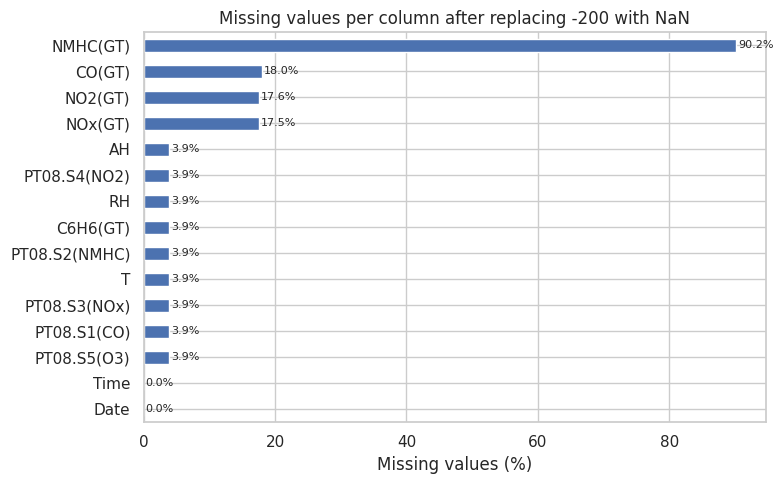

In [22]:
ax = missing_report['missing_pct'].sort_values().plot.barh(figsize=(8, 5), color='#4C72B0')
ax.set_xlabel('Missing values (%)')
ax.set_title('Missing values per column after replacing -200 with NaN')
for i, v in enumerate(missing_report['missing_pct'].sort_values()):
    ax.text(v + 0.3, i, f'{v:.1f}%', va='center', fontsize=8)
plt.tight_layout()
plt.show()

### 2.5 Timestamp construction, ordering, duplicates and chronological gaps
`Date` and `Time` can be stored in different formats depending on the source (the original CSV uses day/month/year dates and `HH.MM.SS` times). Because day/month order is ambiguous for dates such as `3/10/2004`, we try both interpretations and keep the one that is chronologically consistent and matches the documented coverage (10 March 2004 to 4 April 2005).

In [23]:
def build_timestamp(frame, dayfirst):
    d = pd.to_datetime(frame['Date'].astype(str).str.slice(0, 10) if pd.api.types.is_datetime64_any_dtype(frame['Date'])
                       else frame['Date'].astype(str), dayfirst=dayfirst, errors='coerce')
    t = frame['Time'].astype(str).str.replace('.', ':', regex=False).str.slice(0, 8)
    return pd.to_datetime(d.dt.strftime('%Y-%m-%d') + ' ' + t, errors='coerce')

candidates = {}
for dayfirst in (True, False):
    ts = build_timestamp(df, dayfirst)
    n_bad = ts.isna().sum()
    # fraction of consecutive rows that move forward in time (1.0 = perfectly ordered)
    fwd = (ts.diff().dropna() > pd.Timedelta(0)).mean() if n_bad < len(ts) else 0
    candidates[dayfirst] = (ts, n_bad, fwd)
    print(f'dayfirst={dayfirst!s:5} | unparsable={n_bad:5d} | share moving forward={fwd:.4f} | '
          f'range={ts.min()} -> {ts.max()}')

best_dayfirst = max(candidates, key=lambda k: (candidates[k][2], -candidates[k][1]))
df['Timestamp'] = candidates[best_dayfirst][0]
print('\nChosen interpretation: dayfirst =', best_dayfirst)
print('Date coverage:', df['Timestamp'].min(), '->', df['Timestamp'].max())

dayfirst=True  | unparsable= 5760 | share moving forward=1.0000 | range=2004-01-04 00:00:00 -> 2005-12-03 23:00:00
dayfirst=False | unparsable=    0 | share moving forward=1.0000 | range=2004-03-10 18:00:00 -> 2005-04-04 14:00:00

Chosen interpretation: dayfirst = False
Date coverage: 2004-03-10 18:00:00 -> 2005-04-04 14:00:00


In [24]:
ts = df['Timestamp']

print('Unparsable timestamps       :', ts.isna().sum())
print('Rows in chronological order :', ts.is_monotonic_increasing)
print('Duplicate timestamps        :', ts.duplicated().sum())
print('Fully duplicated rows       :', df.duplicated().sum())

# Gaps: hourly data should have a 1-hour step between consecutive rows
ts_sorted = ts.sort_values()
steps = ts_sorted.diff().dropna()
print('\nTime step between consecutive observations:')
print(steps.value_counts().head(10))

full_range = pd.date_range(ts_sorted.min(), ts_sorted.max(), freq='h')
missing_hours = full_range.difference(ts_sorted)
print(f'\nExpected hourly slots: {len(full_range)} | present: {ts_sorted.nunique()} | missing hours: {len(missing_hours)}')

# Largest gaps
gaps = steps[steps > pd.Timedelta(hours=1)].sort_values(ascending=False)
print('\nLargest gaps (end of gap -> length):')
for end, length in gaps.head(5).items():
    print(f'  {end}  ->  {length}')

Unparsable timestamps       : 0
Rows in chronological order : True
Duplicate timestamps        : 0
Fully duplicated rows       : 0

Time step between consecutive observations:
Timestamp
0 days 01:00:00    9356
Name: count, dtype: int64

Expected hourly slots: 9357 | present: 9357 | missing hours: 0

Largest gaps (end of gap -> length):


### 2.6 Implausible values and outliers
We look at physical plausibility first (ranges that make sense for the quantity), then at statistical outliers. Genuine extreme pollution hours are real information and are **not** removed.

In [25]:
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
CO(GT),7674.0,2.15,1.45,0.10,1.10,1.8,2.90,11.90
NMHC(GT),914.0,218.81,204.46,7.00,67.00,150.0,297.00,1189.00
C6H6(GT),8991.0,10.08,7.45,0.10,4.40,8.2,14.00,63.70
NOx(GT),7718.0,246.90,212.98,2.00,98.00,180.0,326.00,1479.00
NO2(GT),7715.0,113.09,48.37,2.00,78.00,109.0,142.00,340.00
PT08.S1(CO),8991.0,1099.83,217.08,647.00,937.00,1063.0,1231.00,2040.00
PT08.S2(NMHC),8991.0,939.15,266.83,383.00,734.50,909.0,1116.00,2214.00
PT08.S3(NOx),8991.0,835.49,256.82,322.00,658.00,806.0,969.50,2683.00
PT08.S4(NO2),8991.0,1456.26,346.21,551.00,1227.00,1463.0,1674.00,2775.00
PT08.S5(O3),8991.0,1022.91,398.48,221.00,731.50,963.0,1273.50,2523.00


In [26]:
# Plausibility checks (physical bounds)
checks = {
    'RH outside 0-100 %'         : (df['RH'] < 0) | (df['RH'] > 100),
    'AH negative'                : df['AH'] < 0,
    'Any concentration negative' : (df[['CO(GT)', 'NMHC(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)']] < 0).any(axis=1),
    'Any sensor response <= 0'   : (df[[c for c in num_cols if c.startswith('PT08')]] <= 0).any(axis=1),
    'T outside -20..50 deg C'    : (df['T'] < -20) | (df['T'] > 50),
}
print(pd.Series({k: int(v.sum()) for k, v in checks.items()}, name='rows flagged').to_frame())

# Statistical outliers (IQR rule), reported only -- not removed
iqr_rows = []
for c in num_cols:
    s = df[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    iqr_rows.append((c, int(((s < lo) | (s > hi)).sum()), round(100 * ((s < lo) | (s > hi)).mean(), 2)))
pd.DataFrame(iqr_rows, columns=['column', 'IQR_outliers', 'pct']).set_index('column')

                            rows flagged
RH outside 0-100 %                     0
AH negative                            0
Any concentration negative             0
Any sensor response <= 0               0
T outside -20..50 deg C                0


,IQR_outliers,pct
column,,
CO(GT),215,2.80
NMHC(GT),55,6.02
C6H6(GT),228,2.54
NOx(GT),435,5.64
NO2(GT),107,1.39
PT08.S1(CO),118,1.31
PT08.S2(NMHC),65,0.72
PT08.S3(NOx),241,2.68
PT08.S4(NO2),97,1.08


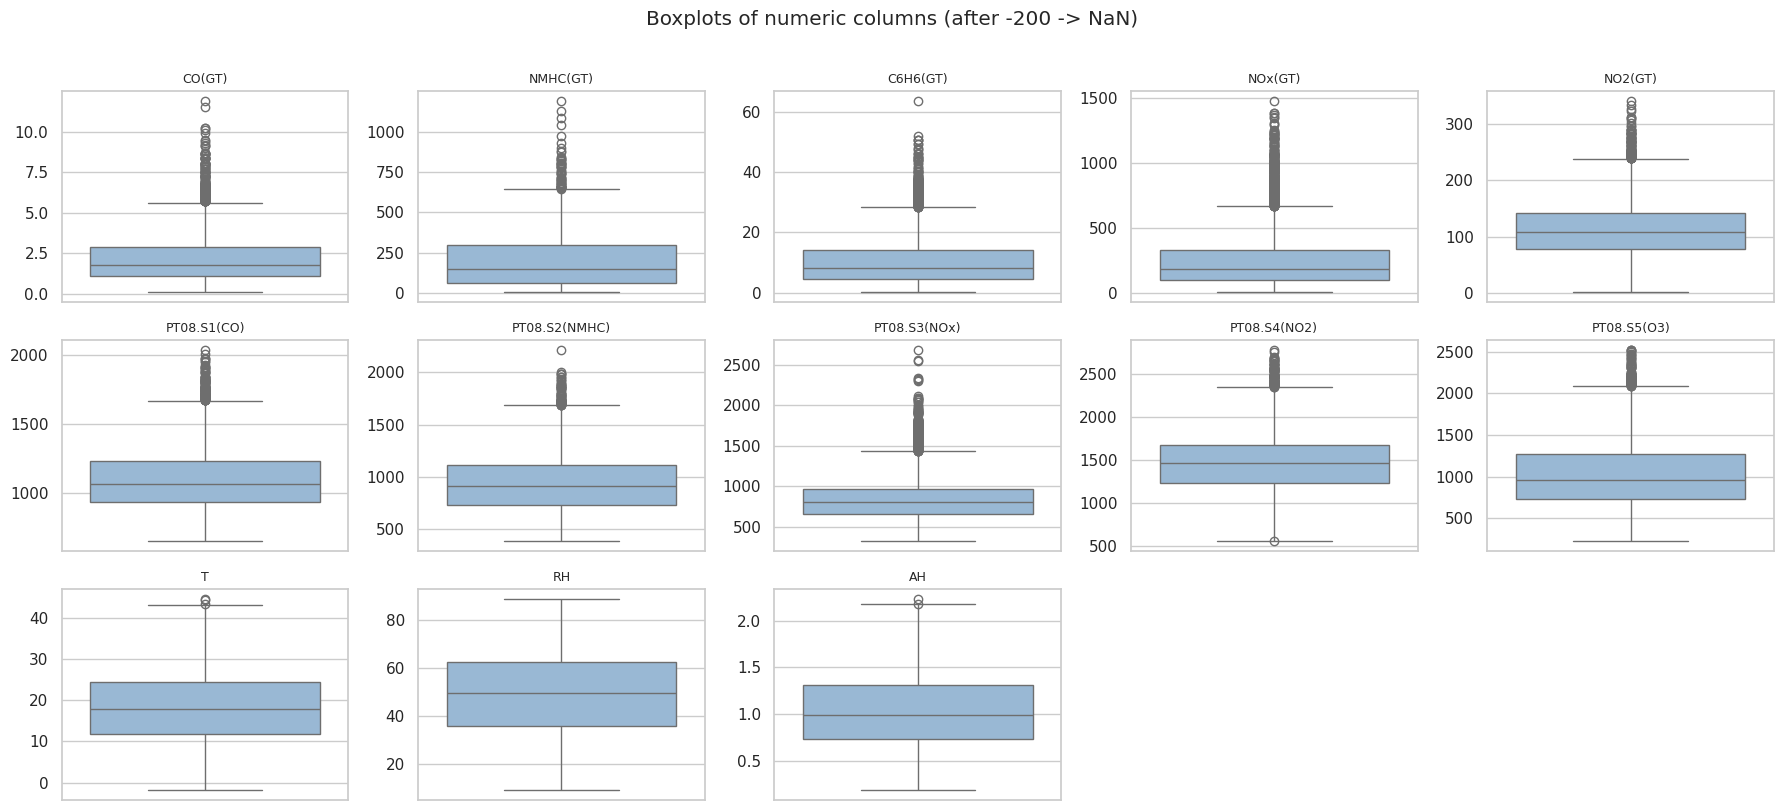

In [27]:
fig, axes = plt.subplots(3, 5, figsize=(18, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[c], ax=ax, color='#8FB8DE')
    ax.set_title(c, fontsize=9)
    ax.set_ylabel('')
for ax in axes.ravel()[len(num_cols):]:
    ax.axis('off')
fig.suptitle('Boxplots of numeric columns (after -200 -> NaN)', y=1.01)
plt.tight_layout()
plt.show()

### 2.7 Target: `CO(GT)` availability and distribution
We do **not** impute the target. Rows with a missing `CO(GT)` cannot be used for supervised training or evaluation and are dropped in Part 3 (they are kept in the notebook only as potential gap-filling cases for the stakeholder).

Total rows            : 9357
Usable target rows    : 7674 (82.0%)
Missing target rows   : 1683 (18.0%)

count    7674.000
mean        2.153
std         1.453
min         0.100
25%         1.100
50%         1.800
75%         2.900
max        11.900
Name: CO(GT), dtype: float64

Skewness: 1.37 | Kurtosis: 2.668


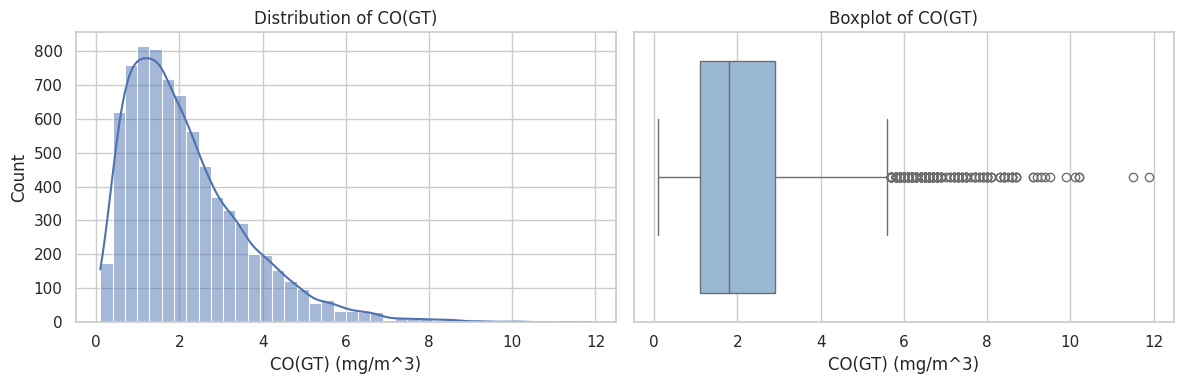

In [28]:
target = 'CO(GT)'
n_total = len(df)
n_usable = df[target].notna().sum()
print(f'Total rows            : {n_total}')
print(f'Usable target rows    : {n_usable} ({100*n_usable/n_total:.1f}%)')
print(f'Missing target rows   : {n_total - n_usable} ({100*(n_total-n_usable)/n_total:.1f}%)')
print()
print(df[target].describe().round(3))
print('\nSkewness:', round(df[target].skew(), 3), '| Kurtosis:', round(df[target].kurt(), 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[target].dropna(), bins=40, kde=True, ax=axes[0], color='#4C72B0')
axes[0].set_title('Distribution of CO(GT)')
axes[0].set_xlabel('CO(GT) (mg/m^3)')
sns.boxplot(x=df[target].dropna(), ax=axes[1], color='#8FB8DE')
axes[1].set_title('Boxplot of CO(GT)')
axes[1].set_xlabel('CO(GT) (mg/m^3)')
plt.tight_layout()
plt.show()

In [29]:
# Is the target missing at random, or concentrated in certain periods? (matters for generalisation)
tmp = df.assign(month=df['Timestamp'].dt.to_period('M'), target_missing=df[target].isna())
monthly = tmp.groupby('month')['target_missing'].agg(['sum', 'count'])
monthly['pct_missing'] = (100 * monthly['sum'] / monthly['count']).round(1)
monthly.columns = ['missing_target_rows', 'rows', 'pct_missing']
monthly

,missing_target_rows,rows,pct_missing
month,,,
2004-03,18,510,3.5
2004-04,225,720,31.2
2004-05,152,744,20.4
2004-06,76,720,10.6
2004-07,186,744,25.0
2004-08,267,744,35.9
2004-09,164,720,22.8
2004-10,351,744,47.2
2004-11,41,720,5.7


### 2.8 Target leakage and predictor availability assessment
Framing: **same-hour estimation** of `CO(GT)` (see Part 1). The table summarises what each predictor group means for leakage and availability. Complete the "evidence" column after Part 4.

| Predictor group | Available at prediction time? | Leakage risk | Handling |
|---|---|---|---|
| `PT08.*` sensor responses | Yes, low-cost sensors run continuously | Low. Independent hardware, though `PT08.S1(CO)` is physically related to CO by design | Core predictors |
| `T`, `RH`, `AH` | Yes, weather probe on the same station | Low | Include |
| Time features (hour, weekday, month) | Always | None | Include |
| `NOx(GT)`, `NO2(GT)`, `C6H6(GT)` | Only if the reference analyzers are running | Medium for deployment: they come from the same reference instrument family and can be missing when `CO(GT)` is missing, so they may not exist in the very gap-filling cases we want to serve. Also strongly co-emitted with CO (traffic) | Compare two feature sets: with and without them |
| `NMHC(GT)` | Rarely | High missingness (see 2.4) | Likely excluded; decide in Part 3 |
| Future values of any column | No | Would be leakage | Not used |

**Check for later (Part 3/4):** among rows where `CO(GT)` is missing, how often are the other reference pollutants also missing? If they are usually missing together, a model that depends on them cannot fill the gaps it is meant to fill.

In [30]:
# Quick look at the co-missingness question raised above
ref_cols = ['NOx(GT)', 'NO2(GT)', 'C6H6(GT)']
co_missing = df[target].isna()
summary = pd.DataFrame({
    'missing when CO(GT) missing (%)': df.loc[co_missing, ref_cols].isna().mean() * 100,
    'missing when CO(GT) present (%)': df.loc[~co_missing, ref_cols].isna().mean() * 100,
}).round(1)
summary

,missing when CO(GT) missing (%),missing when CO(GT) present (%)
NOx(GT),72.8,5.4
NO2(GT),72.8,5.4
C6H6(GT),2.1,4.3


**Part 2 status:** structure verified, data dictionary written, `-200` investigated and replaced with `NaN`, missing-value report, timestamp/duplicate/gap checks, outlier and plausibility checks, target distribution and leakage assessment done.

**Things to write up in your own words after running:** which `-200` evidence convinced you, the exact missing-value percentages (notably `NMHC(GT)`), the chosen date format, the number of missing hours, and the target's skewness.

**Next (Part 3):** data preparation: drop missing-target rows, drop or keep `NMHC(GT)`, sort chronologically, and build the leakage-safe preprocessing pipeline.